Original dataF shape: (1868, 262)
Original dataC shape: (262, 5)
Transposed dataF shape: (262, 1868)


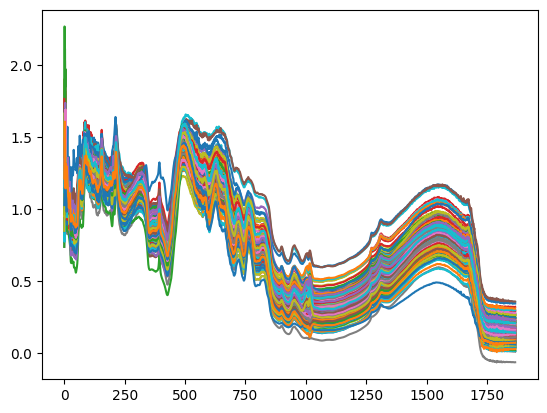

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

 
dataF = pd.read_csv("dataF.csv", header=None)
dataC = pd.read_csv("dataC.csv", header=None)

 
dataF = dataF.values
dataC = dataC.values

 
print("Original dataF shape:", dataF.shape)
print("Original dataC shape:", dataC.shape)
 
dataF_transposed = dataF.T
print("Transposed dataF shape:", dataF_transposed.shape)

 
np.savetxt("dataF_transposed.csv", dataF_transposed, delimiter=",", fmt="%.6f")


plt.plot(dataF)


In [2]:
import numpy as np
from scipy.signal import savgol_filter

# 1. Remove NaN rows
mask = ~np.isnan(dataF_transposed).any(axis=1) & ~np.isnan(dataC).any(axis=1)
X = dataF_transposed[mask]
Y = dataC[mask]

# 2. Savitzky–Golay smoothing + 1st derivative (critical!)
X_sg = savgol_filter(X, window_length=17, polyorder=4, deriv=1, axis=1)

# 3. Standard Normal Variate (correct implementation)
X_snv = (X_sg - X_sg.mean(axis=1, keepdims=True)) / X_sg.std(axis=1, keepdims=True)

# FINAL PREPROCESSED DATA
X_processed = X_snv


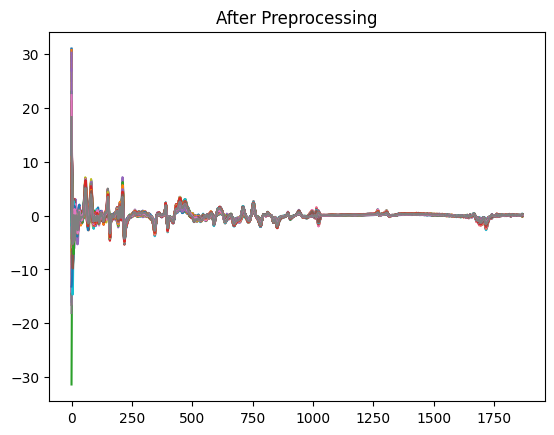

In [3]:
visualize = X_processed.T
plt.plot(visualize, label="SNV Corrected")
plt.title("After Preprocessing")
plt.show()

In [41]:
print("Global feature summary:")
print("Min of mins:", np.min(np.min(X_processed, axis=0)))
print("Max of maxs:", np.max(np.max(X_processed, axis=0)))
print("Mean of means:", np.mean(np.mean(X_processed, axis=0)))
print("Mean of stds:", np.mean(np.std(X_processed, axis=0)))

Global feature summary:
Min of mins: -31.3898991599382
Max of maxs: 31.04380404685343
Mean of means: 7.607523937474306e-18
Mean of stds: 0.17245981502435107


In [15]:
np.savetxt("waves.csv", X_processed, delimiter=",", fmt="%.6f")
np.savetxt("enzymes.csv", Y, delimiter=",", fmt="%.6f")   